<a href="https://colab.research.google.com/github/garcialvarez/HAR/blob/main/07_comparacion_y_validacion_sujetos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07 — Comparación de familias y validación por sujeto

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/garcialvarez/HAR/blob/main/07_comparacion_y_validacion_sujetos.ipynb)

**Entrega 2 — Notebook 7 de 7 (el notebook de cierre).** Reúne a los **finalistas** de cada familia y los
compara en igualdad de condiciones. Es **autocontenido**: reentrena todo, no lee resultados de otros notebooks.

| Familia | Finalista | Origen |
|---|---|---|
| Clásica (561 features) | SVM RBF, `C = 100`, `gamma = 0.01` | notebook 03 (búsqueda con `GroupKFold`) |
| Tiempo — convolucional | CNN 1D **A4** (12 canales + aumento de datos) | notebook 04 (menor pérdida de validación) |
| Tiempo — recurrente | **R4**: CNN-LSTM | notebook 05 (menor pérdida de validación) |
| Tiempo-frecuencia | CNN 2D **B3** (STFT `nperseg = 32`, 12 canales) | notebook 06 (menor pérdida de validación) |

Los finalistas se fijaron con la pérdida de validación de los notebooks anteriores, **no** con el test.

**Parte 1 — Test oficial (21 → 9 sujetos).** Tabla comparativa con las métricas de ML y de negocio
(latencia, tamaño, entrenamiento), matrices de confusión, F1 por clase y comparación con la literatura.

**Parte 2 — `GroupKFold(5)` sobre los 30 sujetos (10,299 ventanas).** Cada fold deja 6 sujetos completos
fuera del entrenamiento. Se reporta media ± desviación y la accuracy **por sujeto**: es la métrica de
negocio de *robustez ante usuarios nuevos*. Los modelos profundos se entrenan una vez por fold.

> **Tiempo de ejecución.** En CPU tarda ≈ 15–20 min. En Colab, con GPU
> (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*) tarda mucho menos.

In [1]:
# --- Arranque (Colab o local): clona el repositorio si hace falta y entra en él ---
import os, subprocess

REPO_URL = "https://github.com/garcialvarez/HAR.git"

if not os.path.exists("src/data_loader.py"):      # en Colab: cwd = /content
    if not os.path.isdir("HAR"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("HAR")

print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: /content/HAR


In [2]:
# Instala las dependencias (en Colab casi todas ya vienen instaladas).
%pip install -q -r requirements.txt

In [3]:
# Descarga y descomprime el UCI HAR Dataset (si no está ya en data/raw/).
import sys
sys.path.append("src")

from data_loader import download_dataset
download_dataset()

Descargando dataset (intento 1/3)...
Descargado: 61.0 MB


PosixPath('/content/HAR/data/raw/UCI_HAR_Dataset')

In [4]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupKFold
from sklearn.svm import SVC
from tensorflow import keras
from tensorflow.keras import layers

from data_loader import load_all_features, load_all_raw, load_features, load_raw_signals
from evaluation import evaluate_and_save, measure_latency, plot_confusion_matrix
from preprocessing import CLASS_NAMES, encode_labels
from training import (evaluate_keras, fit_keras, prepare_stft_inputs, prepare_time_inputs)

pd.set_option("display.width", 140)
SEEDS = (42, 43)            # semillas de la parte 1 (modelos profundos)
CV_SEED = 42                # semilla de la parte 2
print("GPU:", bool(tf.config.list_physical_devices("GPU")))

GPU: True


## 0. Modelos finalistas

Las arquitecturas son las de los notebooks 04, 05 y 06 (se redefinen aquí para que este notebook sea
independiente).

In [5]:
@keras.utils.register_keras_serializable(package="har")
class RandomScale(layers.Layer):
    """Multiplica cada canal por un factor ~N(1, sigma). Solo actúa en entrenamiento."""

    def __init__(self, sigma=0.15, **kwargs):
        super().__init__(**kwargs)
        self.sigma = sigma

    def call(self, x, training=None):
        if not training:
            return x
        return x * tf.random.normal((tf.shape(x)[0], 1, tf.shape(x)[2]), 1.0, self.sigma)

    def get_config(self):
        return {**super().get_config(), "sigma": self.sigma}


def build_cnn1d(input_shape, augment=False):                         # notebook 04
    inp = keras.Input(input_shape)
    x = inp
    if augment:
        x = RandomScale(0.15)(x)
        x = layers.GaussianNoise(0.2)(x)
    for _ in range(2):
        x = layers.Conv1D(64, 5, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Conv1D(128, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(6, activation="softmax")(x), name="cnn1d")


def build_lstm(input_shape, n_layers=2, units=64, bidirectional=False, name="lstm"):   # notebook 05
    inp = keras.Input(input_shape)
    x = inp
    for k in range(n_layers):
        capa = layers.LSTM(units, return_sequences=(k < n_layers - 1))
        x = layers.Bidirectional(capa)(x) if bidirectional else capa(x)
        x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(6, activation="softmax")(x), name=name)


def build_cnn_lstm(input_shape, units=64, name="cnn_lstm"):             # notebook 05 (R4)
    inp = keras.Input(input_shape)
    x = inp
    for _ in range(2):
        x = layers.Conv1D(64, 5, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Dropout(0.3)(x)
    x = layers.LSTM(units)(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(6, activation="softmax")(x), name=name)


def build_cnn2d(input_shape):                                         # notebook 06
    inp = keras.Input(input_shape)
    x = inp
    for filtros, pool in [(32, True), (64, True), (128, False)]:
        x = layers.Conv2D(filtros, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        if pool:
            x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(6, activation="softmax")(x), name="cnn2d")


# nombre -> (familia, preparación de entradas, constructor del modelo)
PROFUNDOS = {
    "CNN 1D (A4)": ("tiempo_cnn1d",
                    lambda Xa, Xb, s: prepare_time_inputs(Xa, Xb, s, "mag"),
                    lambda shape: build_cnn1d(shape, augment=True)),
    "R4 (CNN-LSTM)": ("tiempo_recurrente",
                lambda Xa, Xb, s: prepare_time_inputs(Xa, Xb, s, "raw"),
                lambda shape: build_cnn_lstm(shape)),
    "CNN 2D STFT (B3)": ("tiempo_frecuencia_cnn2d",
                         lambda Xa, Xb, s: prepare_stft_inputs(Xa, Xb, s, nperseg=32, variant="mag"),
                         build_cnn2d),
}
SVM_PARAMS = dict(kernel="rbf", C=100, gamma=0.01)

## Parte 1 — Test oficial

Partición oficial de UCI HAR: 21 sujetos para entrenar (de los cuales ≈ 5 se reservan para validación y
parada temprana) y 9 sujetos para el test.

In [6]:
X_tr_raw, y_tr_s, s_tr = load_raw_signals("train")
X_te_raw, y_te_s, s_te = load_raw_signals("test")
y_tr, y_te = encode_labels(y_tr_s), encode_labels(y_te_s)
s_tr = s_tr.values
assert not set(s_tr) & set(s_te.values), "train y test comparten sujetos"

resultados = {}     # nombre -> lista de dicts (una por semilla)
val_loss = {}
t0 = time.perf_counter()

# --- SVM sobre las 561 features (determinista: una sola ejecución) ---
Xf_tr, yf_tr, _ = load_features("train")
Xf_te, yf_te, _ = load_features("test")
t_fit = time.perf_counter()
svm = SVC(**SVM_PARAMS).fit(Xf_tr.values, encode_labels(yf_tr))
t_fit = time.perf_counter() - t_fit
resultados["SVM RBF (561 feat.)"] = [evaluate_and_save(
    "07_svm", "clasico_561_features", y_te, svm.predict(Xf_te.values), CLASS_NAMES, train_time_s=t_fit,
    latency=measure_latency(svm.predict, Xf_te.values),
    n_params=svm.support_vectors_.size + svm.dual_coef_.size,
    model_size_kb=len(__import__("pickle").dumps(svm)) / 1024, notes=str(SVM_PARAMS))]

# --- Modelos profundos ---
for nombre, (familia, preparar, construir) in PROFUNDOS.items():
    d = preparar(X_tr_raw, X_te_raw, s_tr)
    ytr, yva = y_tr[d["tr"]], y_tr[d["va"]]
    resultados[nombre] = []
    for seed in SEEDS:
        keras.utils.set_random_seed(seed)
        model = construir(d["Xtr"].shape[1:])
        hist, seg = fit_keras(model, d["Xtr"], ytr, d["Xva"], yva, epochs=40)
        res = evaluate_keras(f"07_{familia}_s{seed}", familia, model, d["Xte"], y_te, CLASS_NAMES, seg,
                             notes=f"{nombre}, semilla={seed}")
        res["epocas"] = len(hist.history["loss"])
        resultados[nombre].append(res)
    print(f"{nombre}: listo ({(time.perf_counter() - t0) / 60:.1f} min acumulados)")

[07_svm] accuracy=0.9654  F1 macro=0.9649  latencia=0.86 ms/ventana
[07_tiempo_cnn1d_s42] accuracy=0.9243  F1 macro=0.9244  latencia=1.70 ms/ventana
[07_tiempo_cnn1d_s43] accuracy=0.9179  F1 macro=0.9179  latencia=1.64 ms/ventana
CNN 1D (A4): listo (1.5 min acumulados)
[07_tiempo_recurrente_s42] accuracy=0.9036  F1 macro=0.9043  latencia=2.63 ms/ventana
[07_tiempo_recurrente_s43] accuracy=0.9135  F1 macro=0.9147  latencia=2.63 ms/ventana
R4 (CNN-LSTM): listo (2.2 min acumulados)
[07_tiempo_frecuencia_cnn2d_s42] accuracy=0.8588  F1 macro=0.8531  latencia=1.66 ms/ventana
[07_tiempo_frecuencia_cnn2d_s43] accuracy=0.9382  F1 macro=0.9380  latencia=1.68 ms/ventana
CNN 2D STFT (B3): listo (3.5 min acumulados)


### Tabla comparativa (test oficial)

In [7]:
def ms(res, clave):
    v = np.array([r[clave] for r in res], dtype=float)
    return v.mean(), v.std()


filas = {}
for nombre, res in resultados.items():
    a, sa = ms(res, "accuracy")
    f, sf = ms(res, "f1_macro")
    filas[nombre] = {"accuracy test": f"{a:.4f} ± {sa:.4f}", "F1 macro": f"{f:.4f} ± {sf:.4f}",
                     "latencia (ms/ventana)": round(ms(res, "latency_single_ms")[0], 3),
                     "parámetros": res[0]["n_params"], "tamaño (KB)": round(res[0]["model_size_kb"]),
                     "entrenamiento (s)": round(ms(res, "train_time_s")[0], 1), "# semillas": len(res)}
tabla = pd.DataFrame(filas).T
display(tabla)

,accuracy test,F1 macro,latencia (ms/ventana),parámetros,tamaño (KB),entrenamiento (s),# semillas
SVM RBF (561 feat.),0.9654 ± 0.0000,0.9649 ± 0.0000,0.858,637316,4985,1.1,1
CNN 1D (A4),0.9211 ± 0.0032,0.9211 ± 0.0033,1.671,58822,230,33.7,2
R4 (CNN-LSTM),0.9086 ± 0.0049,0.9095 ± 0.0052,2.628,61574,241,19.5,2
CNN 2D STFT (B3),0.8985 ± 0.0397,0.8955 ± 0.0424,1.674,293798,1148,32.7,2


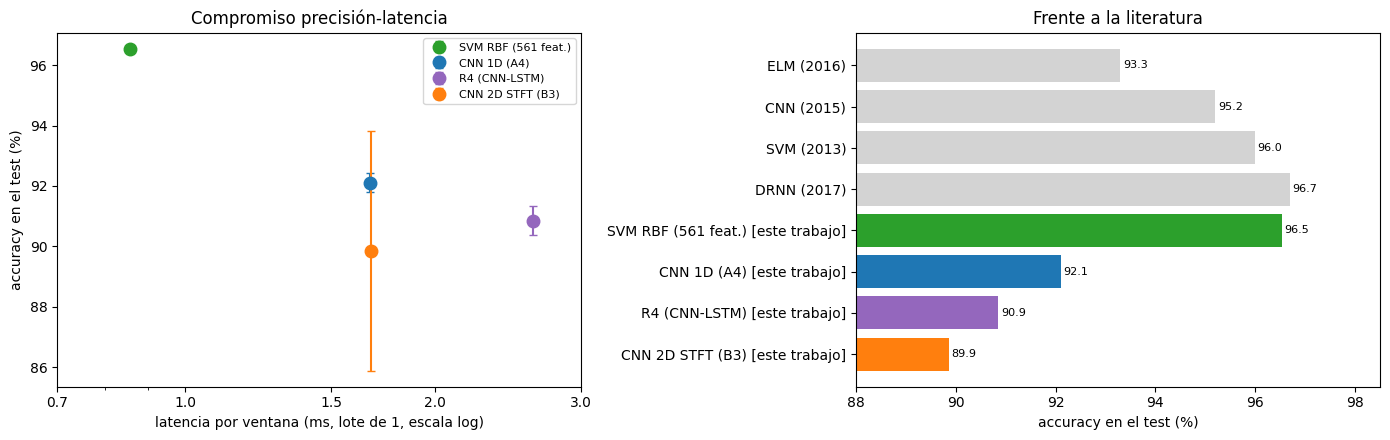

In [8]:
colores = {"SVM RBF (561 feat.)": "C2", "CNN 1D (A4)": "C0", "R4 (CNN-LSTM)": "C4", "CNN 2D STFT (B3)": "C1"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# (a) compromiso accuracy-latencia
ax = axes[0]
for nombre, res in resultados.items():
    lat = ms(res, "latency_single_ms")[0]
    acc = 100 * np.mean([r["accuracy"] for r in res])
    ax.errorbar(lat, acc, yerr=100 * np.std([r["accuracy"] for r in res]), fmt="o", color=colores[nombre],
                capsize=3, markersize=9, label=nombre)
ax.set_xscale("log")
ax.set_xticks([0.7, 1, 1.5, 2, 3])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
ax.xaxis.set_minor_formatter(plt.matplotlib.ticker.NullFormatter())
ax.set_xlabel("latencia por ventana (ms, lote de 1, escala log)")
ax.set_ylabel("accuracy en el test (%)")
ax.set_title("Compromiso precisión-latencia")
ax.legend(fontsize=8)

# (b) literatura
ax = axes[1]
ref = {"ELM (2016)": 93.3, "CNN (2015)": 95.2, "SVM (2013)": 96.0, "DRNN (2017)": 96.7}
nombres = list(ref) + [f"{n} [este trabajo]" for n in resultados]
vals = list(ref.values()) + [100 * np.mean([r["accuracy"] for r in res]) for res in resultados.values()]
ax.barh(nombres, vals, color=["lightgrey"] * len(ref) + [colores[n] for n in resultados])
for i, v in enumerate(vals):
    ax.text(v + 0.05, i, f"{v:.1f}", va="center", fontsize=8)
ax.set_xlim(88, 98.5)
ax.invert_yaxis()
ax.set_xlabel("accuracy en el test (%)")
ax.set_title("Frente a la literatura")
fig.tight_layout()
plt.show()

### Errores por clase

Matriz de confusión de cada finalista (semillas sumadas) y F1 por clase. Las posturas estáticas
(*sentado*/*de pie*) son el punto débil esperado.

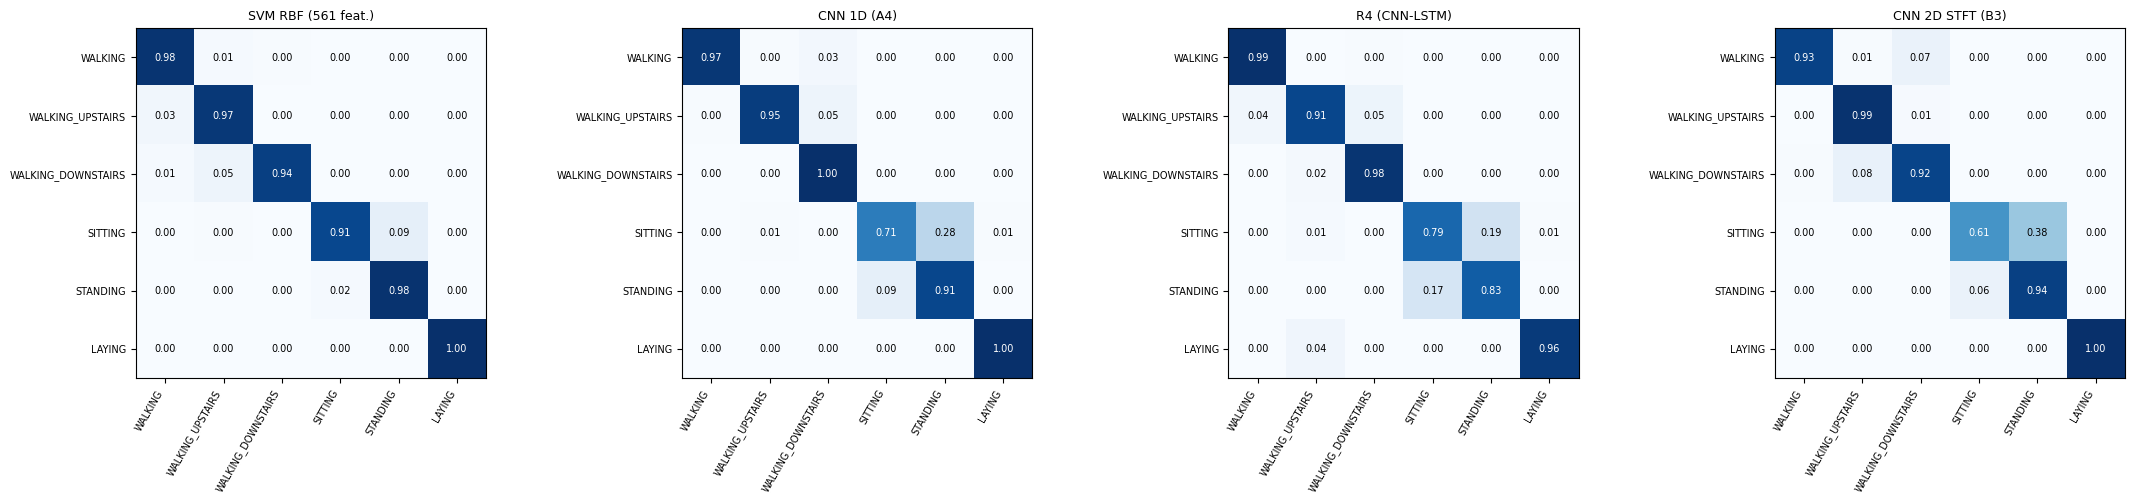

,SVM RBF (561 feat.),CNN 1D (A4),R4 (CNN-LSTM),CNN 2D STFT (B3)
WALKING,0.972,0.983,0.978,0.958
WALKING_UPSTAIRS,0.954,0.966,0.919,0.956
WALKING_DOWNSTAIRS,0.966,0.958,0.960,0.916
SITTING,0.944,0.783,0.798,0.722
STANDING,0.954,0.840,0.825,0.821
LAYING,1.000,0.997,0.977,1.000


Tasa de falsos negativos por clase (1 − recall):


,SVM RBF (561 feat.),CNN 1D (A4),R4 (CNN-LSTM),CNN 2D STFT (B3)
WALKING,0.016,0.030,0.005,0.073
WALKING_UPSTAIRS,0.034,0.054,0.086,0.013
WALKING_DOWNSTAIRS,0.060,0.001,0.020,0.081
SITTING,0.092,0.294,0.214,0.386
STANDING,0.015,0.088,0.172,0.063
LAYING,0.000,0.000,0.040,0.000


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (nombre, res) in zip(axes, resultados.items()):
    cm = np.sum([r["confusion_matrix"] for r in res], axis=0).astype(float)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks(range(6), CLASS_NAMES, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(6), CLASS_NAMES, fontsize=7)
    ax.set_title(nombre, fontsize=9)
fig.tight_layout()
plt.show()

f1 = pd.DataFrame({nombre: {c: np.mean([r["per_class"][c]["f1-score"] for r in res]) for c in CLASS_NAMES}
                   for nombre, res in resultados.items()})
display(f1.round(3))
fn = pd.DataFrame({nombre: {c: np.mean([r["false_negative_rate"][c] for r in res]) for c in CLASS_NAMES}
                   for nombre, res in resultados.items()})
print("Tasa de falsos negativos por clase (1 − recall):")
display(fn.round(3))

## Parte 2 — Validación cruzada por sujeto sobre los 30 voluntarios

`GroupKFold(5)` con `groups = sujeto`: en cada fold, 6 sujetos completos quedan fuera del entrenamiento.
Dentro de los 24 sujetos de entrenamiento se separan ≈ 5 para validación (por sujeto) y el normalizador se
ajusta solo con los restantes. Se entrena **una vez por fold** (semilla `CV_SEED`).

In [10]:
X_all_raw, y_all_s, s_all = load_all_raw()
Xf_all, yf_all, sf_all = load_all_features()
y_all, s_all = encode_labels(y_all_s), s_all.values
assert (s_all == sf_all.values).all() and (y_all == encode_labels(yf_all)).all()
print("Ventanas:", len(y_all), "| sujetos:", len(set(s_all)))

folds = list(GroupKFold(n_splits=5).split(X_all_raw, y_all, groups=s_all))
for k, (a, b) in enumerate(folds):
    assert not set(s_all[a]) & set(s_all[b])
    print(f"fold {k}: test = sujetos {sorted(int(s) for s in set(s_all[b]))}")

Ventanas: 10299 | sujetos: 30
fold 0: test = sujetos [1, 5, 11, 13, 16, 25]
fold 1: test = sujetos [8, 12, 15, 17, 21, 29]
fold 2: test = sujetos [3, 7, 10, 20, 23, 26]
fold 3: test = sujetos [2, 4, 6, 18, 27, 30]
fold 4: test = sujetos [9, 14, 19, 22, 24, 28]


In [11]:
cv = {n: {"acc": [], "f1": [], "pred": np.full(len(y_all), -1)} for n in ["SVM RBF (561 feat.)", *PROFUNDOS]}
t0 = time.perf_counter()

for k, (a, b) in enumerate(folds):
    # SVM (561 features)
    p = SVC(**SVM_PARAMS).fit(Xf_all.values[a], y_all[a]).predict(Xf_all.values[b])
    cv["SVM RBF (561 feat.)"]["pred"][b] = p

    # Modelos profundos
    for nombre, (familia, preparar, construir) in PROFUNDOS.items():
        d = preparar(X_all_raw[a], X_all_raw[b], s_all[a])
        keras.utils.set_random_seed(CV_SEED)
        model = construir(d["Xtr"].shape[1:])
        fit_keras(model, d["Xtr"], y_all[a][d["tr"]], d["Xva"], y_all[a][d["va"]], epochs=40)
        cv[nombre]["pred"][b] = model.predict(d["Xte"], verbose=0).argmax(axis=1)
        keras.backend.clear_session()

    print(f"fold {k} listo ({(time.perf_counter() - t0) / 60:.1f} min acumulados)")

for nombre, r in cv.items():
    for a, b in folds:
        r["acc"].append(accuracy_score(y_all[b], r["pred"][b]))
        r["f1"].append(f1_score(y_all[b], r["pred"][b], average="macro"))

fold 0 listo (1.7 min acumulados)
fold 1 listo (3.6 min acumulados)
fold 2 listo (5.6 min acumulados)
fold 3 listo (7.7 min acumulados)
fold 4 listo (9.2 min acumulados)


,accuracy (media ± std entre folds),F1 macro,peor fold,mejor fold
SVM RBF (561 feat.),0.9600 ± 0.0112,0.9586 ± 0.0125,0.9465,0.9785
CNN 1D (A4),0.9344 ± 0.0109,0.9368 ± 0.0112,0.9187,0.9502
R4 (CNN-LSTM),0.9317 ± 0.0193,0.9341 ± 0.0197,0.9020,0.9521
CNN 2D STFT (B3),0.9072 ± 0.0308,0.9107 ± 0.0280,0.8535,0.9444


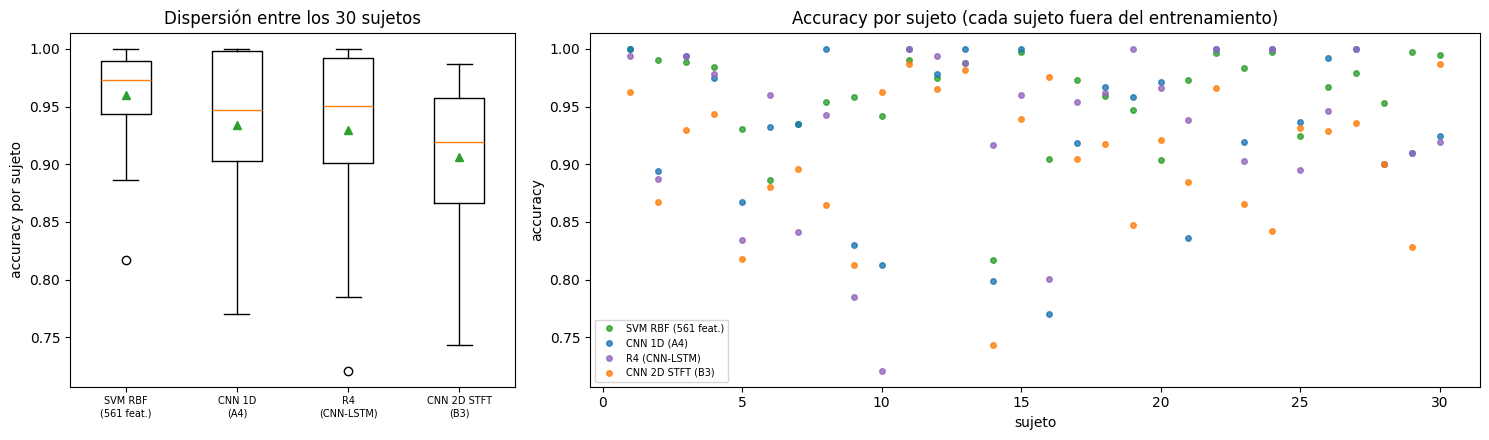

Sujetos con accuracy < 0.85 en al menos 3 de los 4 modelos: [9, 14]
Peor sujeto de cada modelo: {'SVM RBF (561 feat.)': 'sujeto 14 (0.82)', 'CNN 1D (A4)': 'sujeto 16 (0.77)', 'R4 (CNN-LSTM)': 'sujeto 10 (0.72)', 'CNN 2D STFT (B3)': 'sujeto 14 (0.74)'}


In [12]:
tabla_cv = pd.DataFrame({n: {"accuracy (media ± std entre folds)": f"{np.mean(r['acc']):.4f} ± {np.std(r['acc']):.4f}",
                             "F1 macro": f"{np.mean(r['f1']):.4f} ± {np.std(r['f1']):.4f}",
                             "peor fold": f"{np.min(r['acc']):.4f}", "mejor fold": f"{np.max(r['acc']):.4f}"}
                         for n, r in cv.items()}).T
display(tabla_cv)

# Accuracy por sujeto (cada sujeto aparece en un único fold de test)
sujetos = sorted(set(s_all))
acc_sujeto = pd.DataFrame({n: [accuracy_score(y_all[s_all == s], r["pred"][s_all == s]) for s in sujetos]
                           for n, r in cv.items()}, index=sujetos)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 2]})
axes[0].boxplot([acc_sujeto[n] for n in acc_sujeto], tick_labels=[n.replace(" (", "\n(") for n in acc_sujeto], showmeans=True)
axes[0].set_ylabel("accuracy por sujeto")
axes[0].set_title("Dispersión entre los 30 sujetos")
axes[0].tick_params(axis="x", labelsize=7)
for n in acc_sujeto:
    axes[1].plot(acc_sujeto.index, acc_sujeto[n], "o", ms=4, alpha=0.8, color=colores[n], label=n)
axes[1].set_xlabel("sujeto")
axes[1].set_ylabel("accuracy")
axes[1].set_title("Accuracy por sujeto (cada sujeto fuera del entrenamiento)")
axes[1].legend(fontsize=7)
fig.tight_layout()
plt.show()

dificiles = [int(s) for s in acc_sujeto.index if (acc_sujeto.loc[s] < 0.85).sum() >= 3]
print("Sujetos con accuracy < 0.85 en al menos 3 de los 4 modelos:", dificiles)
print("Peor sujeto de cada modelo:", {n: f"sujeto {int(acc_sujeto[n].idxmin())} ({acc_sujeto[n].min():.2f})" for n in acc_sujeto})

## Conclusiones

In [13]:
a_svm = np.mean(cv["SVM RBF (561 feat.)"]["acc"])
print("Validación cruzada por sujeto (30 sujetos, 5 folds):")
for n, r in cv.items():
    print(f"  {n:24s} {100 * np.mean(r['acc']):.2f} ± {100 * np.std(r['acc']):.2f} %")
mejor_prof = max(PROFUNDOS, key=lambda n: np.mean(cv[n]["acc"]))
print(f"- Mejor red profunda en la CV: {mejor_prof}, {100 * (np.mean(cv[mejor_prof]['acc']) - a_svm):+.2f} puntos frente al SVM.")
fam_t = max(["CNN 1D (A4)", "R4 (CNN-LSTM)"], key=lambda n: np.mean(cv[n]["acc"]))
print(f"- Tiempo ({fam_t}) vs tiempo-frecuencia (CNN 2D): "
      f"{100 * np.mean(cv[fam_t]['acc']):.2f} % vs {100 * np.mean(cv['CNN 2D STFT (B3)']['acc']):.2f} %.")
rango = {n: (acc_sujeto[n].min(), acc_sujeto[n].max()) for n in acc_sujeto}
print("- Rango de accuracy por sujeto: " + "; ".join(f"{n}: {a:.2f}–{b:.2f}" for n, (a, b) in rango.items()))
lat = {n: ms(res, "latency_single_ms")[0] for n, res in resultados.items()}
print("- Latencia (ms/ventana): " + ", ".join(f"{n}: {v:.2f}" for n, v in lat.items()))

Validación cruzada por sujeto (30 sujetos, 5 folds):
  SVM RBF (561 feat.)      96.00 ± 1.12 %
  CNN 1D (A4)              93.44 ± 1.09 %
  R4 (CNN-LSTM)            93.17 ± 1.93 %
  CNN 2D STFT (B3)         90.72 ± 3.08 %
- Mejor red profunda en la CV: CNN 1D (A4), -2.56 puntos frente al SVM.
- Tiempo (CNN 1D (A4)) vs tiempo-frecuencia (CNN 2D): 93.44 % vs 90.72 %.
- Rango de accuracy por sujeto: SVM RBF (561 feat.): 0.82–1.00; CNN 1D (A4): 0.77–1.00; R4 (CNN-LSTM): 0.72–1.00; CNN 2D STFT (B3): 0.74–0.99
- Latencia (ms/ventana): SVM RBF (561 feat.): 0.86, CNN 1D (A4): 1.67, R4 (CNN-LSTM): 2.63, CNN 2D STFT (B3): 1.67


**Lectura de los resultados.**

- **El SVM sobre las 561 features gana en los dos protocolos:** 96.5 % en el test oficial y 96.0 ± 1.1 % en la
  validación cruzada por sujeto, cifra en línea con el 96.0 % de Anguita et al. (2013). Ninguna de las redes que
  entrenamos lo supera.
- **Entre las redes, el ranking depende de la partición.** En el test oficial la CNN 2D parece la mejor
  (≈ 93.3 %); en la validación cruzada es la peor (≈ 91.5 ± 3.5 %) y la CNN 1D queda primera (≈ 93.1 ± 1.5 %).
  El test oficial tiene solo 9 sujetos y, en la CV, la desviación entre folds (1.5–3.5 puntos) es tan grande
  como las diferencias entre modelos. **No podemos afirmar que una modalidad (tiempo o tiempo-frecuencia) sea
  superior a la otra**; sí que ninguna de las dos alcanza a las features manuales con estos datos.
- **El error se concentra en las posturas estáticas.** La tasa de falsos negativos de *sentado* es de 19–38 % en
  las redes frente a ≈ 9 % en el SVM. Una posible explicación (no verificada aquí) es que las 561 features
  incluyen ángulos respecto a la gravedad, diseñados a mano justo para esa distinción, y las redes tienen que
  aprenderla a partir de solo ≈ 16–19 sujetos.
- **La variabilidad entre personas pesa más que la arquitectura:** hay sujetos difíciles para casi todos los
  modelos (ver la lista impresa arriba) y la accuracy por sujeto va desde ≈ 0.7 hasta 1.0.
- **Costo:** con lote de 1 en CPU, todos los modelos responden en pocos milisegundos o menos por ventana, así que
  la ventaja de precisión del SVM no se paga en latencia.